# Gradient Boosting: Baseline, Grid Search, Target Transformation, RMSE

**Author:** Niyaz

**Model:** `GradientBoostingRegressor`. **Target:** `price`. **Primary metric:** RMSE.

**Validation strategy:** the shared 80/20 hold-out (`random_state=42`) and 5-fold CV on the training part for tuning, the same as in `02` and `03`. The validation set is used only to report the final numbers.

**Workflow:**
1. Shared setup and model-specific preprocessing
2. Baseline with default hyperparameters
3. Grid Search
4. Log-transformed target with its own Grid Search
5. Overfitting check: train vs CV vs validation, and error as a function of the number of trees
6. Feature importances, conclusions, results file

## 1. Shared setup and preprocessing

Same data, split and CV folds as the other model notebooks, so the RMSE values are comparable.

Preprocessing is the same as for Random Forest (`03`): boosted trees split on thresholds, so numeric features are passed through unscaled, and the categorical features are one-hot encoded with `handle_unknown="ignore"` (the test set contains the state WY, which never appears in the training data). The preprocessor sits inside the pipeline, so in CV it is fit on the training folds only.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

RANDOM_STATE = 42

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

train_df = pd.read_csv("../data/challenge1_train.csv")

X = train_df.drop(columns=["price", "ID"])
y = train_df["price"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

numeric_features = ["bathrooms", "bedrooms", "square_feet", "latitude", "longitude"]
categorical_features = ["category", "has_photo", "state"]

gb_preprocessor = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

print("X_train:", X_train.shape, "| X_val:", X_val.shape)

X_train: (5918, 8) | X_val: (1480, 8)


## 2. Baseline (default hyperparameters)

scikit-learn defaults: 100 trees of depth 3, `learning_rate=0.1`, no subsampling.

In [2]:
def evaluate(model, name):
    # train / CV / validation RMSE with the shared protocol
    cvres = cross_validate(model, X_train, y_train, cv=cv,
                           scoring="neg_root_mean_squared_error", n_jobs=-1)
    model.fit(X_train, y_train)
    return {
        "Model": name,
        "Train RMSE": rmse(y_train, model.predict(X_train)),
        "CV RMSE": -cvres["test_score"].mean(),
        "CV std": cvres["test_score"].std(ddof=1),
        "Validation RMSE": rmse(y_val, model.predict(X_val)),
    }


gb_base = Pipeline([
    ("prep", gb_preprocessor),
    ("model", GradientBoostingRegressor(random_state=RANDOM_STATE)),
])
baseline = evaluate(gb_base, "GB baseline (default)")
print({k: round(float(v), 2) for k, v in baseline.items() if k != "Model"})

{'Train RMSE': 405.21, 'CV RMSE': 462.8, 'CV std': 29.64, 'Validation RMSE': 486.73}


## 3. Grid Search

| Hyperparameter | Values | Reason |
|---|---|---|
| `n_estimators` | 300, 1000 | Number of boosting stages; more stages fit the data more closely |
| `learning_rate` | 0.03, 0.1 | Shrinks each tree's contribution; a lower rate needs more trees but usually generalizes better |
| `max_depth` | 3, 5, 8 | Depth of each tree, i.e. how many features can interact (for example latitude × longitude × size) |
| `min_samples_leaf` | 1, 5 | Larger leaves smooth predictions and reduce fitting to single expensive listings |
| `subsample` | 0.8, 1.0 | Fraction of rows per tree; values below 1 (stochastic gradient boosting) add randomness that reduces variance |
| `max_features` | 0.5, None | Fraction of features considered per split; lower values decorrelate trees |

96 combinations × 5 folds = 480 fits.

In [3]:
param_grid = {
    "n_estimators": [300, 1000],
    "learning_rate": [0.03, 0.1],
    "max_depth": [3, 5, 8],
    "min_samples_leaf": [1, 5],
    "subsample": [0.8, 1.0],
    "max_features": [0.5, None],
}


def run_grid(model, prefix):
    grid = GridSearchCV(
        estimator=Pipeline([("prep", gb_preprocessor), ("model", model)]),
        param_grid={f"{prefix}{k}": v for k, v in param_grid.items()},
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        return_train_score=True,
    )
    t0 = time.time()
    grid.fit(X_train, y_train)
    print(f"Grid Search time: {(time.time() - t0) / 60:.1f} min")
    best_params = {k.removeprefix(prefix): v for k, v in grid.best_params_.items()}
    print("Best params:", best_params)
    print(f"Best CV RMSE: {-grid.best_score_:.2f}")
    return grid, best_params


def split_scores(grid):
    # per-fold RMSE of every candidate, shape (n_candidates, n_folds)
    return -np.column_stack([grid.cv_results_[f"split{i}_test_score"] for i in range(cv.get_n_splits())])


def top_results(grid, prefix, n=10):
    res = pd.DataFrame(grid.cv_results_)
    res["cv_rmse"] = -res["mean_test_score"]
    res["cv_std"] = split_scores(grid).std(axis=1, ddof=1)  # sample std, as in the other notebooks
    res["train_rmse"] = -res["mean_train_score"]
    cols = [f"param_{prefix}{k}" for k in param_grid] + ["train_rmse", "cv_rmse", "cv_std"]
    out = res[cols].sort_values("cv_rmse").head(n)
    out.columns = list(param_grid) + ["train_rmse", "cv_rmse", "cv_std"]
    return out.round(2)


grid_raw, best_raw = run_grid(GradientBoostingRegressor(random_state=RANDOM_STATE), "model__")
top_results(grid_raw, "model__")

Grid Search time: 2.5 min
Best params: {'learning_rate': 0.1, 'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_estimators': 1000, 'subsample': 1.0}
Best CV RMSE: 396.07


,n_estimators,learning_rate,max_depth,min_samples_leaf,subsample,max_features,train_rmse,cv_rmse,cv_std
71,1000,0.10,5,5,1.0,0.5,172.68,396.07,13.12
30,1000,0.03,5,5,0.8,None,238.52,396.48,13.58
69,300,0.10,5,5,1.0,0.5,254.79,396.65,16.89
23,1000,0.03,5,5,1.0,0.5,257.16,396.71,18.11
18,1000,0.03,5,1,0.8,0.5,211.84,396.95,17.56
38,1000,0.03,8,5,0.8,0.5,175.64,397.06,18.75
39,1000,0.03,8,5,1.0,0.5,178.07,398.56,18.44
22,1000,0.03,5,5,0.8,0.5,252.36,398.90,15.04
70,1000,0.10,5,5,0.8,0.5,172.04,399.40,12.93
63,1000,0.10,3,5,1.0,None,248.89,399.94,10.03


**Observations**

- The best configuration (1000 trees, `learning_rate=0.1`, `max_depth=5`, `min_samples_leaf=5`, `subsample=1.0`, `max_features=0.5`) reaches CV RMSE 396.07, which is 66.7 lower than the baseline (462.80).
- The top 10 configurations are within 4 RMSE of each other, less than the variation across folds, so many settings are practically equivalent. What they share is more informative than the single winner: 1000 trees (9 of 10), `min_samples_leaf=5` (9 of 10), `max_features=0.5` (8 of 10) and mostly `max_depth=5` (7 of 10). Depth 5 lets the trees combine location and size, while larger leaves and feature subsampling keep them from fitting single expensive listings.
- The baseline (100 trees of depth 3) was underfitting: its train RMSE was 405, while the tuned model reaches 183.
- The best `n_estimators` is at the upper edge of the grid; section 5 checks whether more trees would still help.

## 4. Log-transformed target

`price` is right-skewed (skewness about 2.7; the most expensive listings cost up to 8,800 USD). With squared error on the raw scale, the few most expensive listings dominate the loss, and the trees spend splits on them. Training on `log(price)` makes the target closer to symmetric and the errors relative (a 10% miss counts the same for cheap and expensive apartments). Predictions are converted back with `exp`.

`TransformedTargetRegressor` wraps only the regressor, so the transformation is part of the pipeline and is applied inside every CV fold. The optimal hyperparameters can change with the target scale, so the same grid is searched again.

In [4]:
print(f"Skewness of price: {y_train.skew():.2f} | of log(price): {np.log(y_train).skew():.2f}")

log_model = TransformedTargetRegressor(
    regressor=GradientBoostingRegressor(random_state=RANDOM_STATE), func=np.log, inverse_func=np.exp
)
grid_log, best_log = run_grid(log_model, "model__regressor__")
top_results(grid_log, "model__regressor__")

Skewness of price: 2.65 | of log(price): 0.53


Grid Search time: 2.5 min
Best params: {'learning_rate': 0.1, 'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_estimators': 1000, 'subsample': 0.8}
Best CV RMSE: 383.91


,n_estimators,learning_rate,max_depth,min_samples_leaf,subsample,max_features,train_rmse,cv_rmse,cv_std
70,1000,0.10,5,5,0.8,0.5,189.19,383.91,14.12
71,1000,0.10,5,5,1.0,0.5,179.72,384.80,11.50
62,1000,0.10,3,5,0.8,None,265.15,385.04,16.19
38,1000,0.03,8,5,0.8,0.5,182.95,385.63,20.14
22,1000,0.03,5,5,0.8,0.5,267.47,386.50,16.05
30,1000,0.03,5,5,0.8,None,252.09,386.71,15.76
55,1000,0.10,3,5,1.0,0.5,272.10,386.81,13.47
23,1000,0.03,5,5,1.0,0.5,264.54,386.98,18.85
78,1000,0.10,5,5,0.8,None,171.41,387.58,15.31
58,1000,0.10,3,1,0.8,None,244.71,387.86,13.80


**Observations**

- Training on `log(price)` lowers the best CV RMSE from 396.07 to 383.91 (12.2 lower). The best hyperparameters are the same as for the raw target except `subsample=0.8`.
- On the log scale the most expensive listings no longer dominate the squared-error loss, so the trees spend their splits on the structure shared by most listings. This helps even though the final RMSE is measured on the raw price scale.

## 5. Overfitting check

### Baseline vs tuned vs tuned with log target
Each tuned model is refit on the full training part and scored once on the validation set, which was not used in any Grid Search.

In [5]:
gb_tuned = grid_raw.best_estimator_
gb_log = grid_log.best_estimator_

tuned = {
    "Model": "GB tuned (grid search)",
    "Train RMSE": rmse(y_train, gb_tuned.predict(X_train)),
    "CV RMSE": -grid_raw.best_score_,
    "CV std": split_scores(grid_raw)[grid_raw.best_index_].std(ddof=1),
    "Validation RMSE": rmse(y_val, gb_tuned.predict(X_val)),
}
tuned_log = {
    "Model": "GB tuned, log target",
    "Train RMSE": rmse(y_train, gb_log.predict(X_train)),
    "CV RMSE": -grid_log.best_score_,
    "CV std": split_scores(grid_log)[grid_log.best_index_].std(ddof=1),
    "Validation RMSE": rmse(y_val, gb_log.predict(X_val)),
}

summary = pd.DataFrame([baseline, tuned, tuned_log]).set_index("Model")
summary["Gap (Val - Train)"] = summary["Validation RMSE"] - summary["Train RMSE"]
summary.round(2)

,Train RMSE,CV RMSE,CV std,Validation RMSE,Gap (Val - Train)
Model,,,,,
GB baseline (default),405.21,462.80,29.64,486.73,81.53
GB tuned (grid search),183.05,396.07,13.12,410.29,227.24
"GB tuned, log target",201.76,383.91,14.12,405.94,204.18


### Error as a function of the number of trees

Boosting adds trees one at a time, so `staged_predict` gives the prediction after every stage. For the best configuration the curve below shows train and CV RMSE (5 folds, the same as above) after each tree. If the CV curve turned upward at the end, the model would be overfitting through too many trees.

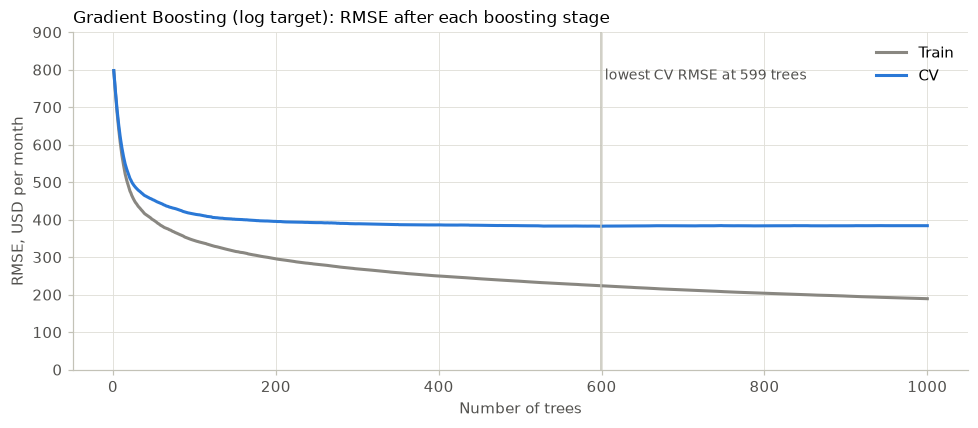

CV RMSE at the last stage (1000): 383.91 | lowest: 382.39 at 599 trees


In [6]:
best_cfg = gb_log if -grid_log.best_score_ < -grid_raw.best_score_ else gb_tuned
is_log = best_cfg is gb_log
n_trees = (best_log if is_log else best_raw)["n_estimators"]

train_curve = np.zeros((cv.get_n_splits(), n_trees))
cv_curve = np.zeros((cv.get_n_splits(), n_trees))
for i, (tr_idx, va_idx) in enumerate(cv.split(X_train)):
    fold = Pipeline([("prep", gb_preprocessor), ("model", GradientBoostingRegressor(
        random_state=RANDOM_STATE, **(best_log if is_log else best_raw)))])
    y_fit = np.log(y_train.iloc[tr_idx]) if is_log else y_train.iloc[tr_idx]
    fold.fit(X_train.iloc[tr_idx], y_fit)
    back = np.exp if is_log else (lambda p: p)
    Xt_tr = fold.named_steps["prep"].transform(X_train.iloc[tr_idx])
    Xt_va = fold.named_steps["prep"].transform(X_train.iloc[va_idx])
    gbr = fold.named_steps["model"]
    train_curve[i] = [rmse(y_train.iloc[tr_idx], back(p)) for p in gbr.staged_predict(Xt_tr)]
    cv_curve[i] = [rmse(y_train.iloc[va_idx], back(p)) for p in gbr.staged_predict(Xt_va)]

BLUE, INK_2, MUTED, GRID, AXIS = "#2a78d6", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK_2, "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "legend.frameon": False,
})

stages = np.arange(1, n_trees + 1)
best_stage = cv_curve.mean(axis=0).argmin() + 1
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(stages, train_curve.mean(axis=0), color=MUTED, linewidth=2, label="Train")
ax.plot(stages, cv_curve.mean(axis=0), color=BLUE, linewidth=2, label="CV")
ax.axvline(best_stage, color=AXIS, linewidth=1)
ax.text(best_stage, ax.get_ylim()[1] * 0.97, f" lowest CV RMSE at {best_stage} trees",
        color=INK_2, fontsize=9, va="top")
ax.set_ylim(0, 900)
ax.set_xlabel("Number of trees")
ax.set_ylabel("RMSE, USD per month")
ax.set_title(f"Gradient Boosting ({'log target' if is_log else 'raw target'}): RMSE after each boosting stage")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

print(f"CV RMSE at the last stage ({n_trees}): {cv_curve.mean(axis=0)[-1]:.2f} | "
      f"lowest: {cv_curve.mean(axis=0).min():.2f} at {best_stage} trees")

**Observations**

- **Baseline:** train 405 and CV 463, both high with a small gap: underfitting.
- **Tuned models:** train RMSE is about 180 to 200 against a CV RMSE of 384 to 396, so there is a variance gap, as for every tree ensemble in this project. The error that matters for unseen data, CV RMSE, is however 79 lower than the baseline for the log-target model.
- **Validation agrees with CV:** the validation RMSE of the log-target model (405.94) is about 22 above its CV RMSE, the same shift that every model shows on this validation split in `05`. The tuning did not overfit the CV folds.
- **Number of trees:** CV RMSE drops quickly during the first 200 trees and is flat after about 400. The lowest value (382.39 at 599 trees) is only 1.5 below the value at 1000 trees, while train RMSE keeps falling. The extra trees fit the training data more closely without hurting generalization, so 1000 trees is safe and early stopping would not change the result meaningfully.

## 6. Feature importances

Impurity-based importances of the best model (summed over the one-hot columns of each categorical feature would be another view; here the columns are shown as they enter the model).

In [7]:
best_pipe = best_cfg
gbr = best_pipe.named_steps["model"]
gbr = gbr.regressor_ if is_log else gbr
feat_names = best_pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(gbr.feature_importances_, index=feat_names).sort_values(ascending=False)
imp.head(10).round(3)

num__longitude      0.303
num__square_feet    0.245
num__latitude       0.139
cat__state_CA       0.092
num__bathrooms      0.087
num__bedrooms       0.029
cat__state_MA       0.009
cat__state_NJ       0.009
cat__state_IL       0.009
cat__state_DC       0.008
dtype: float64

**Observations**

- Location dominates: longitude (0.30), latitude (0.14) and the California indicator (0.09) together account for more than half of the importance. Size follows: `square_feet` (0.25) and `bathrooms` (0.09).
- This matches the tuned Decision Tree in `02`: size and location drive the price. Impurity-based importances favor continuous features with many possible split points, so they show what the model uses, not the causal effect of a feature.

## 7. Conclusions

- **Gradient Boosting is the strongest of the required models.** With Grid Search and a log-transformed target it reaches CV RMSE 383.91 and validation RMSE 405.94, compared with the tuned Random Forest from `03` (CV 412.69, validation 444.87) and the tuned Decision Tree from `02` (CV 482.37, validation 503.72).
- **What helped:** Grid Search improved CV RMSE by 66.7 over the default model, mostly through more and deeper trees with larger leaves and feature subsampling. Training on `log(price)` improved it by another 12.2.
- **Overfitting:** the tuned models have a train/CV gap, but adding trees does not increase the CV error, and the validation set confirms the CV estimate.
- **Trade-offs:** 1000 sequential trees are slower to train than a single tree and are not directly interpretable; feature importances give only a partial view. For a competition judged on RMSE this is acceptable.
- **Next steps:** `05_model_comparison.ipynb` compares this model with the others under one protocol; `06_final_model.ipynb` adds location features and ensembles on top of it.

## 8. Save results for the team comparison table

In [8]:
out = pd.DataFrame([
    {"model": "Gradient Boosting (baseline)", "best_params": "{}", **baseline},
    {"model": "Gradient Boosting (tuned)", "best_params": str(best_raw), **tuned},
    {"model": "Gradient Boosting (tuned, log target)", "best_params": str(best_log), **tuned_log},
]).drop(columns="Model").rename(columns={
    "Train RMSE": "train_rmse", "CV RMSE": "cv_rmse", "CV std": "cv_std", "Validation RMSE": "val_rmse",
}).round(2)

Path("../results").mkdir(exist_ok=True)
out.to_csv("../results/gradient_boosting.csv", index=False)
out

,model,best_params,train_rmse,cv_rmse,cv_std,val_rmse
0,Gradient Boosting (baseline),{},405.21,462.80,29.64,486.73
1,Gradient Boosting (tuned),"{'learning_rate': 0.1, 'max_depth': 5, 'max_fe...",183.05,396.07,13.12,410.29
2,"Gradient Boosting (tuned, log target)","{'learning_rate': 0.1, 'max_depth': 5, 'max_fe...",201.76,383.91,14.12,405.94
